In [9]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [10]:
from datetime import datetime, timedelta

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
papel = 'ITUB4.SA'
papeis_adicionais = ['BBAS3.SA', 'BBDC4.SA', 'SANB11.SA']

In [13]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [14]:
base = datetime.today().date() - timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
#df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[ITUB4.SA] Cache existente cobre de 2020-01-02 a 2025-06-24.
[ITUB4.SA] Cache cobre período solicitado (2023-01-06 a 2025-06-24).
[ITUB4.SA] Retornando 613 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20220106_20250625.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-06-24.
[^BVSP] Cache cobre período solicitado (2023-01-06 a 2025-06-24).
[^BVSP] Retornando 613 linhas para o período solicitado.
Buscando dados adicionais para ITUB4.SA: ['BBAS3.SA', 'BBDC4.SA', 'SANB11.SA']
<class 'datetime.date'> <class 'datetime.date'>
2023-01-06 2025-06-24
[BBAS3.SA] Cache existente cobre de 2020-01-02 a 2025-06-24.
[BBAS3.SA] Cache cobre período solicitado (2023-01-06 a 2025-06-24).
[BBAS3.SA] Retornando 613 linhas para o período solicitado.
<class 'datetime.date'> <class 'datetime.date'>
2023-01-06 2025-06-24
[BBDC4.SA] Cache existente cobre de 2020-01-02 a 2025-06-25.
[BBDC4.SA] Cache cobre período solicitado (2023-01-06 a 2025-06-24).
[BBDC4.SA] Retornando 613 linha

,open,high,low,close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,volume_ibov,adc_open_BBAS3,adc_high_BBAS3,adc_low_BBAS3,adc_close_BBAS3,adc_volume_BBAS3,adc_pct_change_BBAS3,adc_vol_BBAS3,adc_rsi_BBAS3,adc_macd_BBAS3,adc_macd_signal_BBAS3,adc_macd_hist_BBAS3,adc_tr_BBAS3,adc_atr_BBAS3,adc_atr_pct_BBAS3,adc_tr_pct_BBAS3,adc_mm5_BBAS3,adc_mm20_BBAS3,adc_open_BBDC4,adc_high_BBDC4,adc_low_BBDC4,adc_close_BBDC4,adc_volume_BBDC4,adc_pct_change_BBDC4,adc_vol_BBDC4,adc_rsi_BBDC4,adc_macd_BBDC4,adc_macd_signal_BBDC4,adc_macd_hist_BBDC4,adc_tr_BBDC4,adc_atr_BBDC4,adc_atr_pct_BBDC4,adc_tr_pct_BBDC4,adc_mm5_BBDC4,adc_mm20_BBDC4,adc_open_SANB11,adc_high_SANB11,adc_low_SANB11,adc_close_SANB11,adc_volume_SANB11,adc_pct_change_SANB11,adc_vol_SANB11,adc_rsi_SANB11,adc_macd_SANB11,adc_macd_signal_SANB11,adc_macd_hist_SANB11,adc_tr_SANB11,adc_atr_SANB11,adc_atr_pct_SANB11,adc_tr_pct_SANB11,adc_mm5_SANB11,adc_mm20_SANB11
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-06-10,36.500000,36.580002,35.970001,36.000000,20363600,-0.001550,0.004243,47.897989,0.326377,0.648744,-0.322367,0.610001,0.682092,0.018947,0.016944,36.211179,37.018098,14.75,0.26,5.5557,135716.0000,137369.000000,135716.0000,136436.00000,8186500,21.879999,21.910000,21.299999,21.540001,43092300,-0.008744,0.008875,16.998014,-1.585610,-1.361361,-0.224250,0.610001,0.627295,0.029122,0.028319,21.914,24.3185,15.990000,16.040001,15.770000,15.830000,27623200,-0.000631,0.012149,61.067912,0.522653,0.644368,-0.121716,0.270000,0.392295,0.024782,0.017056,16.010,15.820141,29.000000,29.030001,28.540001,28.830000,2133700,0.002783,0.008525,43.999704,0.021428,0.262595,-0.241168,0.490000,0.646290,0.022417,0.016996,28.856,29.7485
2025-06-11,35.970001,36.590000,35.740002,36.330002,16180000,0.009167,0.005887,52.229671,0.286704,0.576336,-0.289632,0.849998,0.694086,0.019105,0.023397,36.157009,36.993535,14.75,0.26,5.5390,136443.0000,137531.000000,135628.0000,137128.00000,8767100,21.500000,21.830000,21.400000,21.400000,32228100,-0.006500,0.008730,16.512034,-1.596813,-1.408451,-0.188362,0.430000,0.613203,0.028654,0.020093,21.724,23.9005,15.770000,16.360001,15.650000,16.320000,48251000,0.030954,0.015763,68.281475,0.516125,0.618720,-0.102594,0.710001,0.414988,0.025428,0.043505,15.984,15.877029,29.200001,30.350000,29.090000,30.170000,6945600,0.046479,0.017953,60.279714,0.092219,0.228520,-0.136301,1.520000,0.708698,0.023490,0.050381,29.084,29.7365
2025-06-12,36.090000,36.830002,36.060001,36.610001,21869400,0.007707,0.006465,55.602433,0.274691,0.516007,-0.241316,0.770000,0.699508,0.019107,0.021033,36.248013,36.958212,14.75,0.26,5.5388,137127.0000,137931.000000,136175.0000,137800.00000,7124600,21.389999,21.500000,21.040001,21.420000,28710900,0.000935,0.009433,16.877655,-1.585798,-1.443920,-0.141877,0.459999,0.602260,0.028117,0.021475,21.560,23.5015,16.209999,16.540001,16.139999,16.480000,38328100,0.009804,0.015837,70.221692,0.517893,0.598554,-0.080661,0.400002,0.413918,0.025116,0.024272,16.086,15.934426,30.000000,30.070000,29.610001,29.910000,1390700,-0.008618,0.018180,56.827659,0.125891,0.207994,-0.082104,0.559999,0.698076,0.023339,0.018723,29.278,29.7105
2025-06-13,36.169998,36.349998,35.910000,36.169998,14389900,-0.012019,0.007290,49.667896,0.227048,0.458215,-0.231167,0.700001,0.699543,0.019340,0.019353,36.233180,36.889995,14.75,0.26,5.5652,137800.0000,137800.000000,136586.0000,137213.00000,8628300,21.379999,21.650000,21.240000,21.590000,33033700,0.007937,0.010960,20.081330,-1.545534,-1.464243,-0.081291,0.410000,0.588527,0.027259,0.018990,21.536,23.2975,16.260000,16.450001,16.139999,16.290001,29855200,-0.011529,0.016332,65.127042,0.498220,0.578487,-0.080268,0.340000,0.408638,0.025085,0.020872,16.152,15.979825,29.740000,30.200001,29.440001,29.799999,3141200,-0.003678,0.018202,55.382599,0.142062,0.194808,-0.052746,0.760000,0.702500,0.023574,0.025503,29.492,29.6950
2025-06-16,36.5299

## Verificação da volatilidade recente

In [15]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-06-10,0.682092,0.018947,0.610001,0.016944
2025-06-11,0.694086,0.019105,0.849998,0.023397
2025-06-12,0.699508,0.019107,0.770000,0.021033
2025-06-13,0.699543,0.019340,0.700001,0.019353
2025-06-16,0.724576,0.019674,1.050003,0.028509
2025-06-17,0.695678,0.018777,0.320000,0.008637
2025-06-18,0.672415,0.018257,0.370003,0.010046
2025-06-20,0.655814,0.017899,0.440002,0.012009
2025-06-23,0.643970,0.017614,0.489998,0.013403


In [16]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 1.80%
Valorização sugerida: 2.70%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [17]:
valorizacao = -0.03
stop_loss = 0.02
DIAS_FUTURO = 5  # dias futuros para buscar a valorização

In [18]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

Target
0.0    0.868421
1.0    0.131579
Name: proportion, dtype: float64

In [19]:
# estudo de qual tamanho de janela é melhor para este papel
tamanhos_janela = [6, 10, 15, 20, 30, 60]
f1_treino = []
f1_validacao = []

for tamanho_janela in tamanhos_janela:
    X, y = pp.preparar_X_y_agregado(df, tamanho_janela, dropna=True, tipo_drop_na='linhas')   

    X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)
    X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
    X_validacao = X_validacao[X_train.columns]

    modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
    modelo.fit(X_train.values, y_train.values)

    roc_treino, roc_validacao, diferenca, pr_auc_treino, pr_auc_validacao, f1_score_treino, f1_score_validacao = tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)

    f1_treino.append(f1_score_treino)
    f1_validacao.append(f1_score_validacao)

df_resultados = pd.DataFrame({
    'Tamanho Janela': tamanhos_janela,
    'F1 Treino': f1_treino,
    'F1 Validação': f1_validacao
})

INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'SANB11']
INFO: 29 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.578
AUC na validação: 0.746
Diferença AUC (Treino - Validação): -0.168
PR AUC no treino: 0.311
PR AUC na validação: 0.171
Diferença PR AUC (Treino - Validação): 0.140
F1 Score no treino: 0.231
F1 Score na validação: 0.175
INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'SANB11']
INFO: 25 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.529
AUC na validação: 0.264
Diferença AUC (Treino - Validação): 0.265
PROVÁVEL OVERFITTING
PR AUC no treino: 0.236
PR AUC na validação: 0.070
Diferença PR AUC (Treino - Validação): 0.166
F1 Score no treino: 0.219
F1 Score na validação: 0.051
INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'SANB11']
INFO: 20 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


... (3 outputs left out)

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.603
AUC na validação: 0.516
Diferença AUC (Treino - Validação): 0.087
PR AUC no treino: 0.302
PR AUC na validação: 0.101
Diferença PR AUC (Treino - Validação): 0.201
F1 Score no treino: 0.259
F1 Score na validação: 0.000
INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'SANB11']


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.740
AUC na validação: 0.584
Diferença AUC (Treino - Validação): 0.157
PROVÁVEL OVERFITTING
PR AUC no treino: 0.538
PR AUC na validação: 0.106
Diferença PR AUC (Treino - Validação): 0.432
F1 Score no treino: 0.337
F1 Score na validação: 0.192


In [20]:
df_resultados.sort_values(by='F1 Validação', ascending=False)

,Tamanho Janela,F1 Treino,F1 Validação
5,60,0.336829,0.191507
0,6,0.231137,0.175462
1,10,0.218905,0.051134
2,15,0.273577,0.038278
3,20,0.258441,0.000000
4,30,0.259315,0.000000


In [21]:
# Preparar X e y para treino
DIAS_JANELA_X = 60  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

INFO: Papéis adicionais detectados para features: ['BBAS3', 'BBDC4', 'SANB11']


In [22]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: ['close_mean', 'tr_ultimo_norm_atr_principal', 'close_max', 'volume_mean', 'close_amplitude', 'macd_signal_std', 'dias_queda_pct', 'tr_pct_ultimo', 'close_std_norm_atr_principal', 'macd_ultimo_norm_atr_principal', 'macd_hist_ultimo', 'retorno_mean', 'macd_mean', 'adc_close_trend_BBDC4', 'macd_ultimo', 'close_ult_vs_mm_janela', 'macd_signal_ultimo_norm_atr_principal', 'ibov_std']
Colunas restantes após filtragem: 69


In [23]:
X_train.tail()

,close_std,close_min,close_trend,retorno_desde_mudanca_close,close_dist_min,close_vs_mm20,mm5_vs_mm20,retorno_std,retorno_acumulado,dias_alta_pct,retorno_medio_pos,retorno_medio_neg,volume_std,volume_trend,volume_ult_vs_mean,atr_ultimo,atr_pct_ultimo,rsi_mean,rsi_std,rsi_ultimo,macd_std,macd_std_norm_atr_principal,macd_signal_mean,macd_signal_ultimo,macd_signal_std_norm_atr_principal,macd_hist_mean,macd_hist_std,macd_hist_std_norm_atr_principal,macd_hist_ultimo_norm_atr_principal,tr_mean,tr_std,tr_ultimo,tr_std_norm_atr_principal,tr_pct_mean,tr_pct_std,close_amplitude_norm_atr_principal,adc_close_trend_BBAS3,adc_ret_acum_BBAS3,adc_rsi_ultimo_BBAS3,adc_atr_pct_ultimo_BBAS3,adc_macd_hist_ultimo_BBAS3,adc_correl_com_principal_BBAS3,adc_ret_acum_BBDC4,adc_rsi_ultimo_BBDC4,adc_atr_pct_ultimo_BBDC4,adc_macd_hist_ultimo_BBDC4,adc_correl_com_principal_BBDC4,adc_close_trend_SANB11,adc_ret_acum_SANB11,adc_rsi_ultimo_SANB11,adc_atr_pct_ultimo_SANB11,adc_macd_hist_ultimo_SANB11,adc_correl_com_principal_SANB11,adc_close_mean_geral_ultimo,close_vs_adc_close_mean_geral,adc_atr_pct_mean_geral_ultimo,adc_ret_acum_mean_geral_janela,selic_ultimo,ipca_ultimo,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,retorno_desde_mudanca_ibov,ibov_amplitude,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean
2025-01-28,1.476958,26.819136,-0.064304,0.001805,3.129797,0.049728,0.034912,0.015565,-0.057992,0.450000,0.011716,-0.011503,1.142942e+07,-67980.073354,-0.416407,0.555332,0.018543,42.832622,9.198650,62.792134,0.294303,0.529959,-0.391002,-0.011786,0.430992,0.013170,0.131979,0.237658,0.432685,0.589385,0.253832,0.431696,0.457081,0.019914,0.008521,10.559231,-0.013287,0.051968,76.537468,0.017973,0.343141,0.694411,-0.199742,50.063900,0.025220,0.056357,0.744341,-0.048537,-0.088353,53.332325,0.021433,0.122280,0.698795,21.279009,0.407440,0.021542,-0.078709,12.25,0.16,5.8930,0.006009,0.153545,0.000000,-176.346318,0.000000,12197.0,0.850491,1.182317,0.000084
2025-01-29,1.449035,26.819136,-0.060109,0.000000,3.057852,0.043112,0.034697,0.015515,-0.057589,0.450000,0.011716,-0.011253,1.142075e+07,-114589.549041,-0.509530,0.538149,0.018012,43.056100,9.490662,61.655543,0.303961,0.564827,-0.387120,0.044104,0.454357,0.015529,0.134472,0.249879,0.415423,0.585788,0.256197,0.314779,0.476071,0.019811,0.008597,10.896373,-0.007994,0.040576,74.813826,0.017785,0.318338,0.692854,-0.210634,47.034773,0.025276,0.050487,0.742150,-0.045437,-0.113417,50.870318,0.021207,0.092252,0.719036,21.146684,0.412845,0.021423,-0.094491,12.25,0.16,5.8596,0.005395,0.150555,-0.005668,-168.941650,-0.005030,12128.0,0.850181,1.180433,0.000176
2025-01-30,1.428320,26.819136,-0.054766,0.000000,3.786337,0.062773,0.038413,0.015852,-0.028269,0.466667,0.012168,-0.011517,1.124445e+07,-137553.746874,0.055925,0.561381,0.018342,43.405462,10.010430,67.976363,0.316308,0.563447,-0.382481,0.105966,0.447475,0.018557,0.137631,0.245165,0.440781,0.593283,0.257651,0.863391,0.458960,0.020064,0.008618,10.445450,-0.002105,0.049753,76.101800,0.018101,0.295233,0.692010,-0.129188,60.535203,0.026606,0.084629,0.747552,-0.039686,-0.054044,60.651373,0.021936,0.129333,0.745691,21.734726,0.408137,0.022214,-0.044493,13.25,0.16,5.9006,0.004952,0.148742,0.000000,-155.579105,0.000000,12128.0,0.853888,1.150063,-0.000015
2025-01-31,1.409885,26.819136,-0.050036,0.000000,3.588474,0.049364,0.040364,0.015852,-0.028727,0.466667,0.012168,-0.011515,1.126590e+07,-158680.923312,-0.272790,0.547621,0.018009,43.749331,10.386111,64.849525,0.329985,0.602580,-0.377028,0.164929,0.473832,0.021811,0.140440,0.256455,0.430686,0.590585,0.259162,0.368742,0.473250,0.019985,0.008669,10.707910,0.003711,0.060943,76.362164,0.017713,0.263521,0.690794,-0.116795,59.244522,0.027408,0.099566,0.768259,-0.034706,-0.031343,62.593074,0.021097,0.160288,0.744430,21.808479,0.394302,0.022072,-0.029065,13.25,0.16,5.8301,0.004383,0.147724,0.000000,-144.854404,0.000000,12128.0,0.856629,1.161834,-0.000141
2025-02-03,1.392601,26.819136,-0.046053,-0.009760,3.

# LGBM GOOGLE

## Versão com early stopping

In [24]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 15,
            'max_depth': -1, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

In [25]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (459 amostras):
  - Treino Base LGBM: 368 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 91 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 45, number of negative: 323
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000666 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7819
[LightGBM] [Info] Number of data points in the train set: 368, number of used features: 69
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Li

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.886
AUC na validação: 0.399
Diferença AUC (Treino - Validação): 0.487
PROVÁVEL OVERFITTING
PR AUC no treino: 0.653
PR AUC na validação: 0.051
Diferença PR AUC (Treino - Validação): 0.602
F1 Score no treino: 0.514
F1 Score na validação: 0.000


(np.float64(0.8858059215368587),
 np.float64(0.39913938608157673),
 np.float64(0.48666653545528193),
 np.float64(0.6530649806588268),
 np.float64(0.05130472639692272),
 np.float64(0.5141191282769653),
 np.float64(0.0))

Avaliar e logar modelo
MLflow Run ID: 9f96e576fce2418890a2329c47b5cbf6 para ITUB4.SA_60dias_x_-0.03val_5dias_alvo
AUC no treino: 0.892
AUC na validação: 0.302

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.886
  Precisão média (em 306 janelas com previsão positiva): 0.654
  Recall médio: 0.544

Calibrando thresholds para precisão mínima de 0.65...

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 65.42%
  Recall Médio Esperado: 54.39%
  Janelas Usadas para Precisão: 306.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 4.0
Sinais de compra previstos na validação: 0
Modelo ITUB4.SA_60dias_x_-0.03val_5dias_alvo salvo na run 9f96e576fce2418890a2329c47b5cbf6


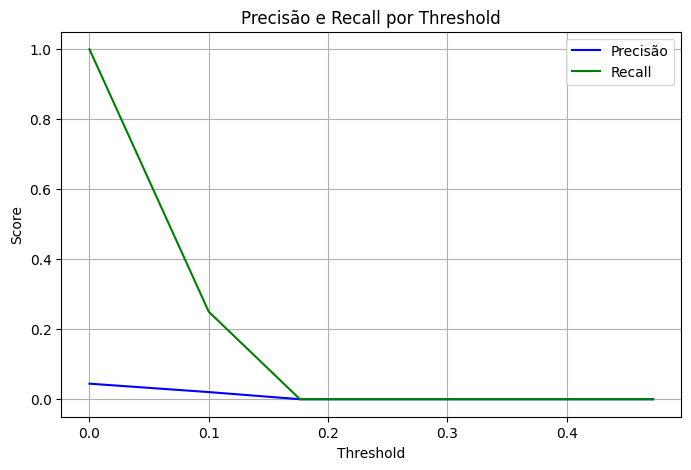

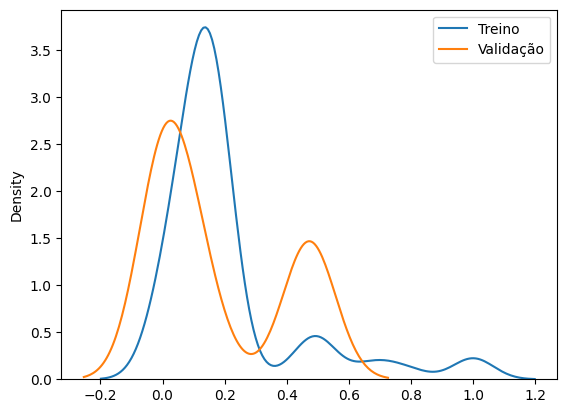

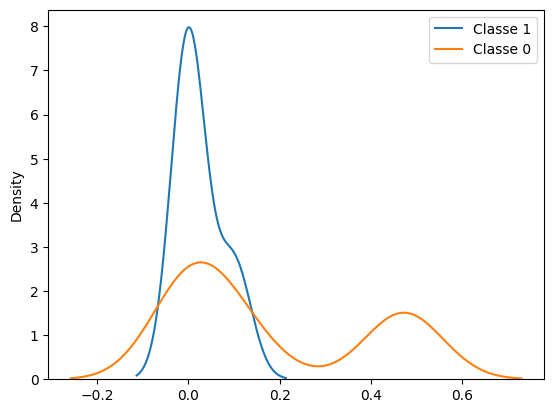

In [26]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [16]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


adc_atr_pct_ultimo_SANB11       81.004398
retorno_mean                    34.791000
adc_ret_acum_BBDC4              33.272301
tr_std                          28.490700
ibov_trend                      21.294800
volume_std                      20.246700
close_std_norm_atr_principal    15.615000
retorno_desde_mudanca_close     13.507200
retorno_medio_pos                2.636370
close_trend                      1.110580
close_max                        0.000000
retorno_medio_neg                0.000000
volume_mean                      0.000000
volume_trend                     0.000000
volume_ult_vs_mean               0.000000
dtype: float64

In [17]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.25, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
#k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 75, number of negative: 288
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000292 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2062
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[L

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Calibração concluída.
Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 75, number of negative: 288
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000421 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2062
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best ga

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

... (230 outputs left out)

Calibração concluída.
Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 75, number of negative: 288
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000254 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2916
[LightGBM] [Info] Number of data points in the train set: 363, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

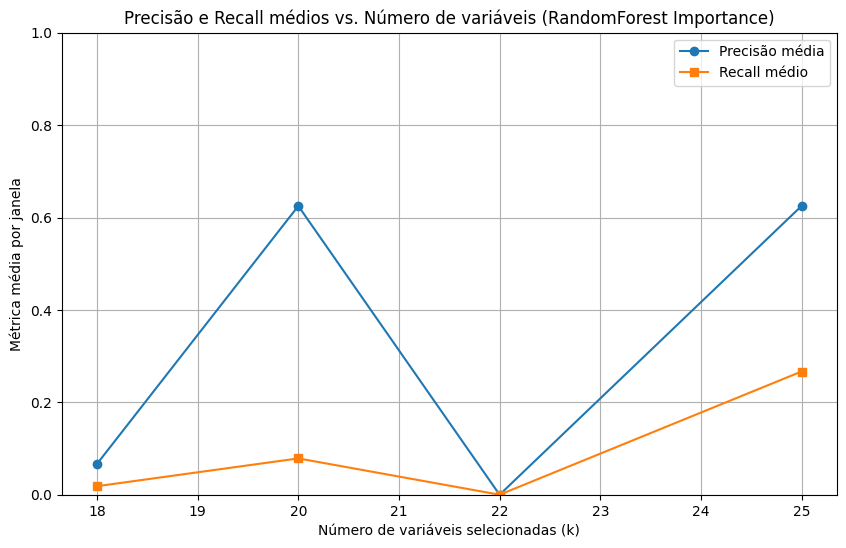

In [18]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [19]:
n_features = 20
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['adc_atr_pct_ultimo_SANB11',
 'retorno_mean',
 'adc_ret_acum_BBDC4',
 'tr_std',
 'ibov_trend',
 'volume_std',
 'close_std_norm_atr_principal',
 'retorno_desde_mudanca_close',
 'retorno_medio_pos',
 'close_trend',
 'close_max',
 'retorno_medio_neg',
 'volume_mean',
 'volume_trend',
 'volume_ult_vs_mean',
 'atr_ultimo',
 'retorno_std',
 'mm5_vs_mm20',
 'close_vs_mm20',
 'rsi_ultimo']

In [20]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [32]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.3, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit',
    metodo_calibracao='isotonic'
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 339 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 145 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
[LightGBM] [Info] Number of positive: 71, number of negative: 268
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000153 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2128
[LightGBM] [Info] Number of data points in the train set: 339, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.917
AUC na validação: 0.601
Diferença AUC (Treino - Validação): 0.316
PROVÁVEL OVERFITTING
PR AUC no treino: 0.786
PR AUC na validação: 0.499
Diferença PR AUC (Treino - Validação): 0.287
F1 Score no treino: 0.558
F1 Score na validação: 0.190


(np.float64(0.9174545656918629),
 np.float64(0.601438704798253),
 np.float64(0.3160158608936099),
 np.float64(0.785776447037615),
 np.float64(0.49905028110364635),
 np.float64(0.5575254538215687),
 np.float64(0.18970712781553772))

Avaliar e logar modelo
MLflow Run ID: fdf7c9cf9c2e4605b4cea4e5a8f5a402 para ITUB4.SA_20dias_x_0.03val_5dias_alvo
AUC no treino: 0.930
AUC na validação: 0.530

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.917
  Precisão média (em 308 janelas com previsão positiva): 0.915
  Recall médio: 0.450

Calibrando thresholds para precisão mínima de 0.75...

Threshold Ideal Selecionado: 0.50
  Precisão Média Esperada: 91.50%
  Recall Médio Esperado: 45.03%
  Janelas Usadas para Precisão: 308.0

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.615
Recall médio: 0.114
Sinais de compra presentes na vallidação: 25.0
Sinais de compra previstos na validação: 14
Modelo ITUB4.SA_20dias_x_0.03val_5dias_alvo salvo na run fdf7c9cf9c2e4605b4cea4e5a8f5a402


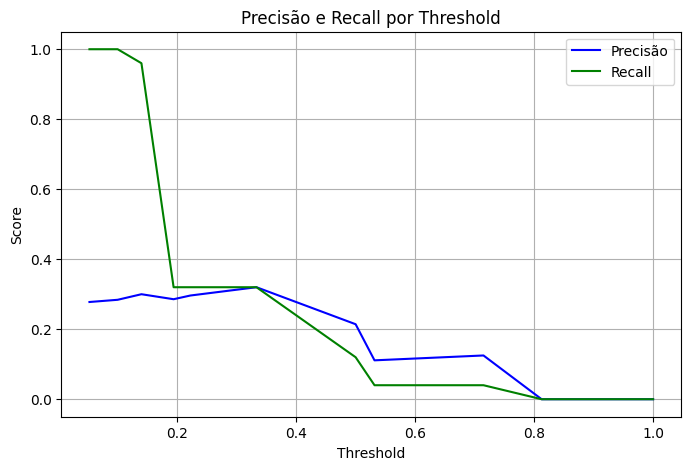

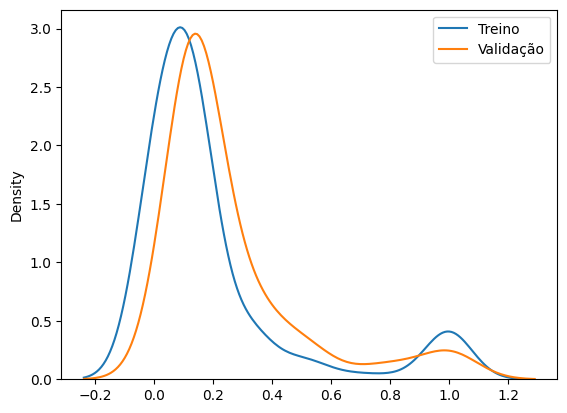

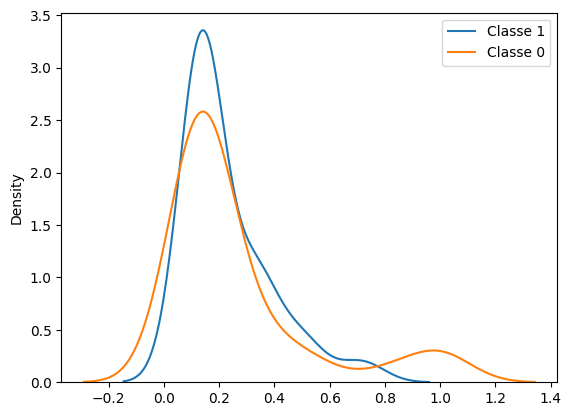

In [33]:
precisao_minima = 0.75
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

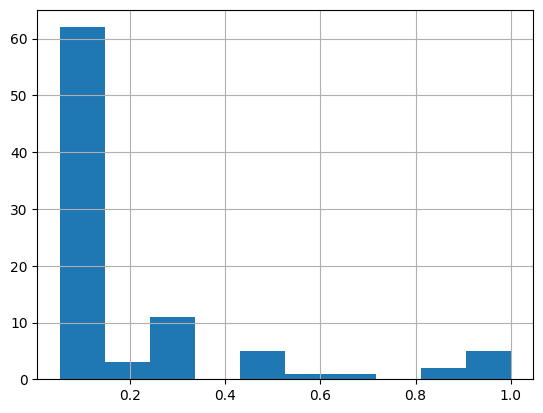

In [34]:
pd.Series(probas).hist()

In [35]:
pd.Series(probas).describe()

count    90.000000
mean      0.254036
std       0.237498
min       0.052632
25%       0.140000
50%       0.140000
75%       0.333333
max       1.000000
dtype: float64